# 3. Egg weight and egg quality

**Author:** Mahdi Dadgar

Egg weight is recorded weekly. Shell breaking strength and Haugh units come from 30 eggs every four weeks. I compared
the same candidates as for the laying curve, on the same 11 held-out farms.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIGURES_DIR, FLOCKS_FILE, QUALITY_FILE, REPORTS_DIR, TRUTH_DIR, WEEKLY_FILE

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
GREEN, GREY, BLUE, ORANGE = "#2E7D32", "#757575", "#1565C0", "#E65100"
STRAIN_COL = {"Lohmann Brown-Classic": ORANGE, "Hy-Line W-80": BLUE}
pd.set_option("display.width", 140)
from src.features import FEATURES, flock_planning_features
from src.predict import get_predictor
from src.truth import true_flock
from src.scenarios import apply_scenario
flocks = pd.read_csv(FLOCKS_FILE)
comp = pd.read_csv(REPORTS_DIR / "planning_model_comparison.csv")
comp[comp.target != "hen_day_pct"].round(3)

,target,model,rmse,mae,r2,response_error
5,egg_weight_g,Breed standard,1.848,1.543,0.875,NaN
6,egg_weight_g,Training average by strain and age,1.908,1.588,0.866,NaN
7,egg_weight_g,"Ridge, broken-line features",1.189,0.967,0.948,0.016
8,egg_weight_g,"XGBoost, monotonic",1.286,1.042,0.939,0.023
9,egg_weight_g,"XGBoost, unconstrained",1.435,1.179,0.924,0.091
10,breaking_strength_n,Breed standard,3.233,2.483,0.765,NaN
11,breaking_strength_n,Training average by strain and age,3.526,2.811,0.721,NaN
12,breaking_strength_n,"Ridge, broken-line features",2.586,2.013,0.850,0.085
13,breaking_strength_n,"XGBoost, monotonic",2.775,2.174,0.827,0.068
14,breaking_strength_n,"XGBoost, unconstrained",2.728,2.148,0.833,0.263


For all three, ridge regression with broken-line terms (the shortfall below requirement, as in requirement studies) does as
well as or better than XGBoost. With effects that are close to linear above and below a requirement, the simpler model wins,
so I use it.

## Shell strength: calcium and coarse limestone

I took one Lohmann Brown-Classic barn flock and changed calcium supply and the share of coarse limestone. The lines are the
model's prediction; the dots are the true response of the synthetic data.

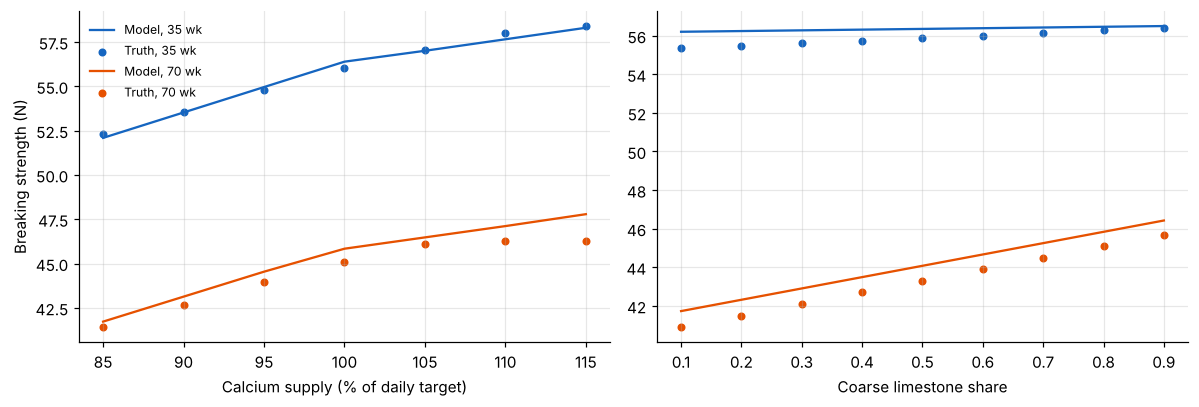

In [2]:
P = get_predictor()
from tests.conftest import make_plan
base = make_plan()
ages = [35, 70]
ca_levels = np.linspace(0.85, 1.15, 7)
coarse_levels = np.linspace(0.1, 0.9, 9)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for age, c in zip(ages, [BLUE, ORANGE]):
    pred, true = [], []
    for lvl in ca_levels:
        p = make_plan(calcium=lvl)
        pred.append(P.predict_plan(p)["weeks"].set_index("age_wk").loc[age, "breaking_strength_n"])
        true.append(true_flock(p).set_index("age_wk").loc[age, "breaking_strength_n"])
    ax[0].plot(ca_levels * 100, pred, color=c, label=f"Model, {age} wk")
    ax[0].scatter(ca_levels * 100, true, color=c, s=18, label=f"Truth, {age} wk")
    pred, true = [], []
    for lvl in coarse_levels:
        p = make_plan(coarse=(lvl, lvl, lvl))
        pred.append(P.predict_plan(p)["weeks"].set_index("age_wk").loc[age, "breaking_strength_n"])
        true.append(true_flock(p).set_index("age_wk").loc[age, "breaking_strength_n"])
    ax[1].plot(coarse_levels, pred, color=c, label=f"Model, {age} wk")
    ax[1].scatter(coarse_levels, true, color=c, s=18, label=f"Truth, {age} wk")
ax[0].set_xlabel("Calcium supply (% of daily target)"); ax[0].set_ylabel("Breaking strength (N)")
ax[1].set_xlabel("Coarse limestone share"); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "03_shell_response.png", bbox_inches="tight"); plt.show()

The model follows the broken-line response to calcium: a steep loss below the requirement and a small gain above it. It
also learned that coarse limestone matters more in old hens, through a coarse-share × age term. The levels differ slightly
from the truth because the truth here is an average farm, and the model's intercept comes from real (synthetic) farms with
heat and disease.

## Egg weight: amino acids

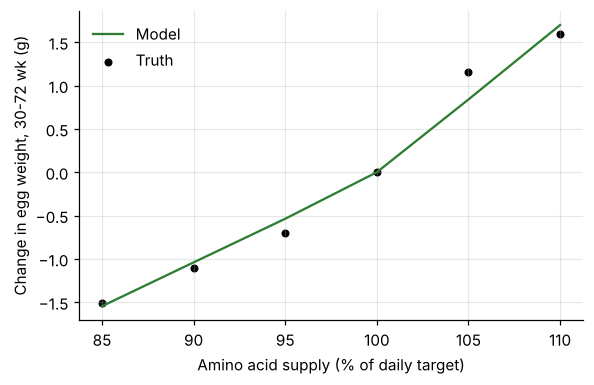

In [3]:
aa_levels = np.linspace(0.85, 1.10, 6)
pred, true = [], []
for lvl in aa_levels:
    p = make_plan(amino_acids=lvl)
    w = P.predict_plan(p)["weeks"]; t = true_flock(p)
    pred.append(w.loc[w.age_wk.between(30, 72), "egg_weight_g"].mean())
    true.append(t.loc[t.age_wk.between(30, 72), "egg_weight_g"].mean())
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(aa_levels * 100, np.array(pred) - pred[3], color=GREEN, label="Model")
ax.scatter(aa_levels * 100, np.array(true) - true[3], color="black", s=18, label="Truth")
ax.set_xlabel("Amino acid supply (% of daily target)"); ax.set_ylabel("Change in egg weight, 30-72 wk (g)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIGURES_DIR / "03_egg_weight_response.png", bbox_inches="tight"); plt.show()

## Haugh units: an honest result

No model does much better than the breed curve for Haugh units (RMSE 2.02 against 2.08). In these data Haugh units fall with
age and drop during respiratory disease and heat; diet has only a small effect through lysine. Disease is not in the
records, and the rest is farm-to-farm and egg-to-egg variation. I kept the ridge model so the app shows a value, but
the breed curve would serve almost as well. On real farms, storage time and temperature would be the first things to record.

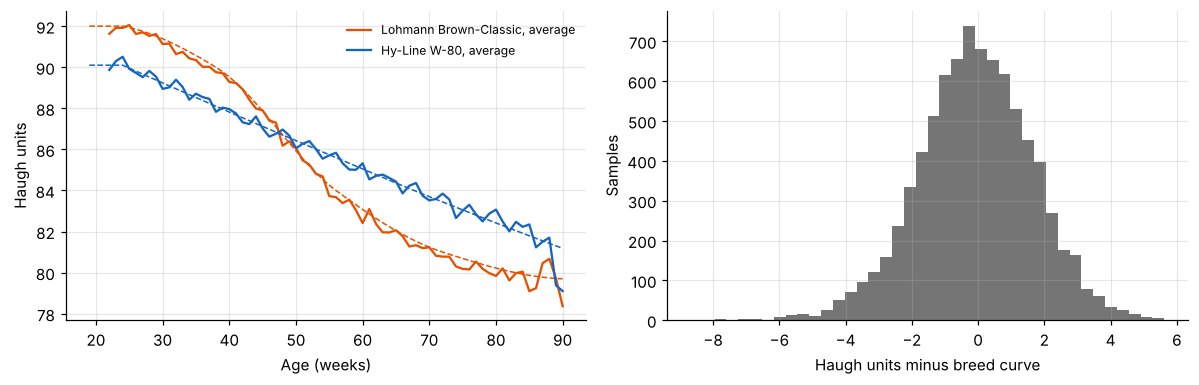

SD of residual around the breed curve: 1.73 HU


In [4]:
q = pd.read_csv(QUALITY_FILE).merge(flocks[["flock_id", "strain"]], on="flock_id")
from src.standards import strain_standard
q["breed_curve"] = [strain_standard(s)["haugh_units"].get(a, np.nan) for s, a in zip(q.strain, q.age_wk)]
q["residual"] = q.haugh_units - q.breed_curve
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s, c in STRAIN_COL.items():
    g = q[q.strain == s].groupby("age_wk").haugh_units.mean()
    ax[0].plot(g.index, g.values, color=c, label=f"{s}, average")
    std = strain_standard(s)
    ax[0].plot(std.index, std.haugh_units, color=c, ls="--", lw=1)
ax[0].set_xlabel("Age (weeks)"); ax[0].set_ylabel("Haugh units"); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(q.residual, bins=40, color=GREY)
ax[1].set_xlabel("Haugh units minus breed curve"); ax[1].set_ylabel("Samples")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "03_haugh_units.png", bbox_inches="tight"); plt.show()
print(f"SD of residual around the breed curve: {q.residual.std():.2f} HU")

## Intervals

The 90 % intervals come from out-of-fold errors on the training farms, by age band. Coverage on the held-out farms:

In [5]:
import json
card = json.load(open("../models/model_card.json"))
pd.DataFrame({t: {"model": v["model"], "RMSE": round(v["test"]["rmse"], 3), "R2": round(v["test"]["r2"], 3),
                  "90 % coverage": round(v["interval_90_coverage_test"], 3)}
              for t, v in card["planning_models"].items()}).T

,model,RMSE,R2,90 % coverage
hen_day_pct,"XGBoost, monotonic",4.603,0.903,0.879
egg_weight_g,"Ridge, broken-line features",1.189,0.948,0.925
breaking_strength_n,"Ridge, broken-line features",2.586,0.85,0.913
haugh_units,"Ridge, broken-line features",2.024,0.716,0.799


Coverage is close to 90 % for egg weight and shell strength and a little under for hen-day production. For Haugh units it is
80 %: the held-out farms happen to differ more from each other in Haugh units than the training farms did. With only 11
held-out farms, coverage depends on a few farm levels, so I report it as it came out rather than widening the intervals after
looking at the test set.